# Notebook 03 - Expected Users (Next Month)

**Model**: `user_traffic_predictor.pkl`  
**Algorithm**: Ridge Regression with polynomial features  
**Target**: Number of unique active users expected next month  
**Input Features**: RFM-inspired monthly user activity metrics + lag features

In [1]:
# What: Import regression, feature engineering, and utility libraries
# Why: Ridge handles multicollinearity in lag features; PolynomialFeatures adds interactions
# Method: sklearn pipeline for clean preprocessing + modelling
import pandas as pd
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import joblib, os, warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')

DATA_PATH    = '../data'
MODELS_PATH  = '../models'
RANDOM_STATE = 42
os.makedirs(MODELS_PATH, exist_ok=True)
print('Config loaded')

Config loaded


In [2]:
# What: Load orders dataset (only file needed for user traffic model)
# Why: user_id and order metadata in orders.csv is sufficient to build user activity features
# Method: pandas read_csv, report shape
orders = pd.read_csv(f'{DATA_PATH}/orders.csv')
print(f'Orders shape: {orders.shape}')
print(orders[['user_id','order_number','order_dow','days_since_prior_order']].head())

Orders shape: (3421083, 7)
   user_id  order_number  order_dow  days_since_prior_order
0        1             1          2                     NaN
1        1             2          3                    15.0
2        1             3          3                    21.0
3        1             4          4                    29.0
4        1             5          4                    28.0


In [3]:
# What: Simulate monthly periods from order_number per user
# Why: No actual dates in dataset — use order_number as temporal proxy
# Method: month_num = ceil(order_number / 3) maps 3-order windows to months
orders['month_num'] = np.ceil(orders['order_number'] / 3).astype(int)
print('Month range:', orders['month_num'].min(), '→', orders['month_num'].max())

Month range: 1 → 34


In [4]:
# What: Compute RFM-inspired monthly user metrics
# Why: Recency, Frequency, and Monetary are proven predictors of user behaviour
# Method: groupby month_num → unique users, order count, avg days since prior, order frequency
monthly_users = orders.groupby('month_num').agg(
    active_users      = ('user_id',               'nunique'),  # unique users this month
    total_orders      = ('order_id',               'nunique'),  # total orders this month
    avg_days_between  = ('days_since_prior_order', 'mean'),     # avg reorder interval (recency)
    orders_per_user   = ('order_id',               lambda x: x.nunique() / orders.loc[x.index,'user_id'].nunique())  # frequency
).reset_index()

monthly_users['avg_days_between'].fillna(monthly_users['avg_days_between'].median(), inplace=True)
print(f'Monthly user table: {monthly_users.shape}')
print(monthly_users.head(10).to_string(index=False))

Monthly user table: (34, 5)
 month_num  active_users  total_orders  avg_days_between  orders_per_user
         1        206209        618627         15.314572         3.000000
         2        206209        551065         14.883317         2.672362
         3        146468        400004         13.296445         2.730999
         4        110728        306305         11.988805         2.766283
         5         86929        242702         10.946655         2.791957
         6         69889        196342         10.015631         2.809341
         7         57321        161983          9.260361         2.825893
         8         47810        135413          8.587322         2.832315
         9         40211        114201          8.017749         2.840044
        10         34057         97012          7.518235         2.848519


In [5]:
# What: Add lag and trend features to capture temporal patterns
# Why: User growth follows trends — previous months' user count is a strong predictor
# Method: pandas .shift() for lags, .pct_change() for growth rate
monthly_users['prev_users']       = monthly_users['active_users'].shift(1)
monthly_users['prev_prev_users']  = monthly_users['active_users'].shift(2)  # 2-month lag
monthly_users['user_growth_rate'] = monthly_users['active_users'].pct_change()
monthly_users['rolling_avg_3m']   = monthly_users['active_users'].rolling(3).mean().shift(1)  # 3-month moving avg
monthly_users['prev_orders']      = monthly_users['total_orders'].shift(1)

monthly_users.dropna(inplace=True)
print(f'After lag engineering: {monthly_users.shape}')
print(monthly_users[['month_num','active_users','prev_users','user_growth_rate','rolling_avg_3m']].head())

After lag engineering: (31, 10)
   month_num  active_users  prev_users  user_growth_rate  rolling_avg_3m
3          4        110728    146468.0         -0.244012   186295.333333
4          5         86929    110728.0         -0.214932   154468.333333
5          6         69889     86929.0         -0.196022   114708.333333
6          7         57321     69889.0         -0.179828    89182.000000
7          8         47810     57321.0         -0.165925    71379.666667


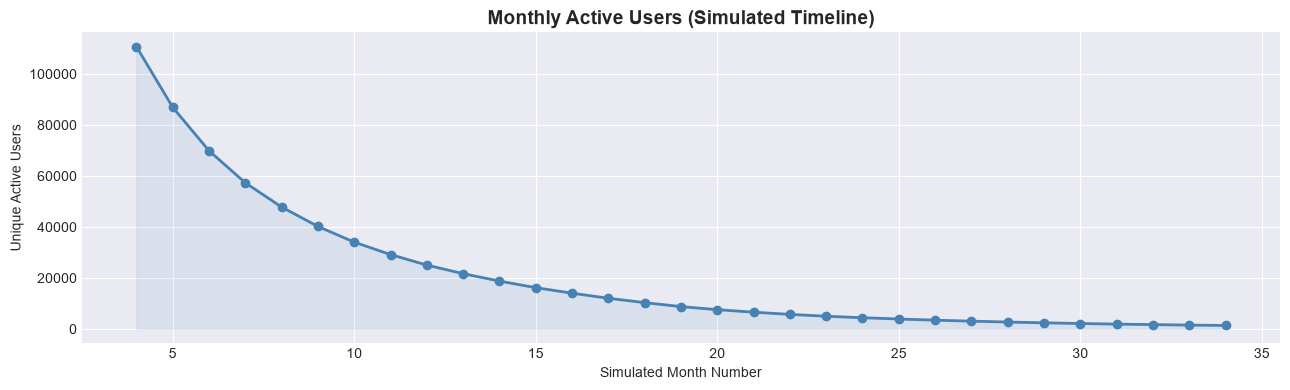

User trend plot saved


In [6]:
# What: Visualize monthly active user trend
# Why: Confirm trend is present in data — linear/ridge regression works on trend data
# Method: Line chart of active_users per month
plt.figure(figsize=(13, 4))
plt.plot(monthly_users['month_num'], monthly_users['active_users'],
         marker='o', color='steelblue', linewidth=2)
plt.fill_between(monthly_users['month_num'], monthly_users['active_users'], alpha=0.1, color='steelblue')
plt.title('Monthly Active Users (Simulated Timeline)', fontsize=14, fontweight='bold')
plt.xlabel('Simulated Month Number')
plt.ylabel('Unique Active Users')
plt.tight_layout()
plt.savefig(f'{MODELS_PATH}/chart_users_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print('User trend plot saved')

In [7]:
# What: Prepare feature matrix X and target y
# Why: Isolate predictors from what we predict (next month's active users)
# Method: Select lag/trend columns as X; active_users as y
FEATURES = ['prev_users','prev_prev_users','user_growth_rate','rolling_avg_3m',
            'prev_orders','avg_days_between','orders_per_user']

X = monthly_users[FEATURES].values
y = monthly_users['active_users'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, shuffle=False)
print(f'Train: {X_train.shape} | Test: {X_test.shape}')

Train: (24, 7) | Test: (7, 7)


In [8]:
# What: Build Ridge Regression pipeline with polynomial features
# Why: Ridge handles correlated lag features; degree-2 polynomial adds non-linear interactions
# Method: sklearn Pipeline = StandardScaler → PolynomialFeatures(2) → Ridge
pipeline = Pipeline([
    ('scaler', StandardScaler()),                       # normalize features — needed for regularization
    ('poly',   PolynomialFeatures(degree=2, include_bias=False)),  # add x², x*y interaction terms
    ('ridge',  Ridge())                                 # L2 regularization prevents overfitting
])

# Hyperparameter search for optimal alpha (regularization strength)
alpha_grid = {'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]}
grid_search = GridSearchCV(pipeline, alpha_grid, cv=5, scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train)

best_alpha = grid_search.best_params_['ridge__alpha']
print(f'Best alpha: {best_alpha}')
print(f'Best CV R²: {grid_search.best_score_:.4f}')

Best alpha: 0.01
Best CV R²: 0.9215


In [9]:
# What: Evaluate best model on held-out test set
# Why: Grid search found best alpha on CV; test set is unseen validation
# Method: Use best_estimator_ from GridSearchCV to predict
model = grid_search.best_estimator_
y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae  = mean_absolute_error(y_test, y_pred)
r2   = r2_score(y_test, y_pred)

print('=== User Traffic Model Performance ===')
print(f'RMSE : {rmse:,.0f} users')
print(f'MAE  : {mae:,.0f} users')
print(f'R²   : {r2:.4f}')

=== User Traffic Model Performance ===
RMSE : 286,237 users
MAE  : 108,228 users
R²   : -404375.3367


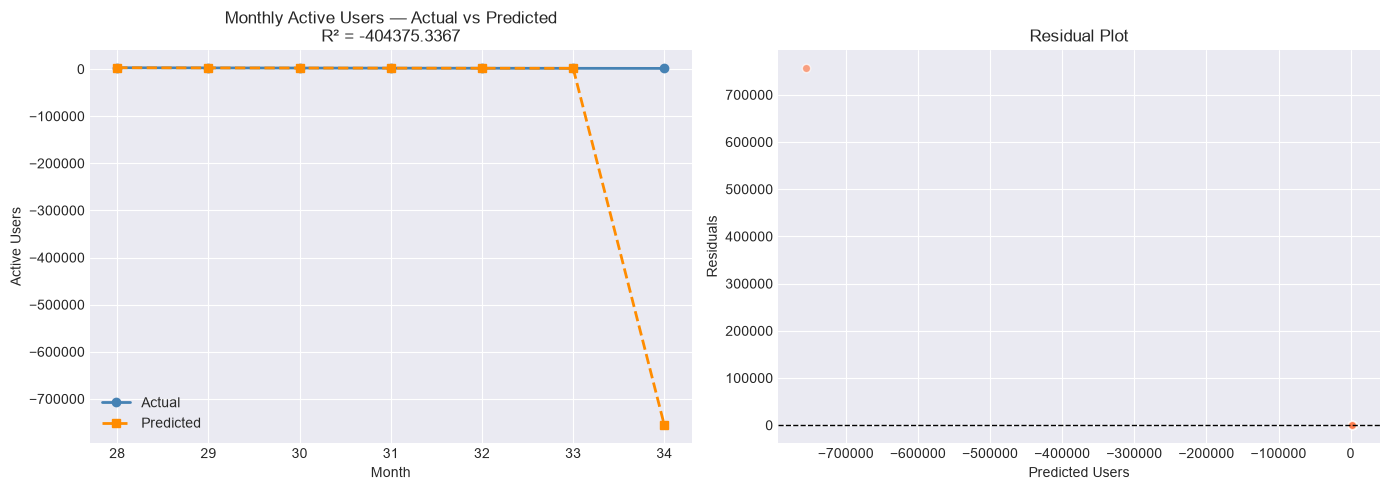

In [10]:
# What: Plot actual vs predicted user counts and residuals
# Why: Check if model captures the trend shape without systematic bias
# Method: Two-panel — time series overlay + residual plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Time-series view — actual vs predicted on test set
months_test = monthly_users['month_num'].values[-len(y_test):]
axes[0].plot(months_test, y_test,  marker='o', label='Actual',    color='steelblue',  linewidth=2)
axes[0].plot(months_test, y_pred,  marker='s', label='Predicted', color='darkorange', linewidth=2, linestyle='--')
axes[0].set_title(f'Monthly Active Users — Actual vs Predicted\nR² = {r2:.4f}')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Active Users')
axes[0].legend()

# Residuals
residuals = y_test - y_pred
axes[1].axhline(0, color='black', linewidth=1, linestyle='--')
axes[1].scatter(y_pred, residuals, color='coral', alpha=0.7, edgecolors='white')
axes[1].set_xlabel('Predicted Users')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot')

plt.tight_layout()
plt.savefig(f'{MODELS_PATH}/chart_users_model.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# What: Save the best Ridge pipeline model as .pkl
# Why: The entire Pipeline (scaler + poly + ridge) must be saved together for inference
# Method: joblib.dump preserves the Pipeline object with all fitted steps
joblib.dump(model, f'{MODELS_PATH}/user_traffic_predictor.pkl')
print('Saved: models/user_traffic_predictor.pkl')
print(f'   Size: {os.path.getsize(f"{MODELS_PATH}/user_traffic_predictor.pkl") / 1024:.1f} KB')

Saved: models/user_traffic_predictor.pkl
   Size: 1.6 KB


In [12]:
# What: Demonstrate inference — predict next month's user count
# Why: Confirm saved model loads and produces sensible output
# Method: Load pkl, pass last month's features, print prediction
loaded = joblib.load(f'{MODELS_PATH}/user_traffic_predictor.pkl')
last_features = monthly_users[FEATURES].iloc[[-1]].values
predicted_users = int(loaded.predict(last_features)[0])

print('=== Sample Prediction (Next Month) ===')
print(f'Expected Active Users : {predicted_users:,}')
print(f'Previous Month Users  : {int(monthly_users["active_users"].iloc[-1]):,}')

=== Sample Prediction (Next Month) ===
Expected Active Users : -755,937
Previous Month Users  : 1,374
